# 01 · Main model: development and evaluation

Produces:
- **Table 3**, all studies: held-out test-set performance (RMSE, MAE, R², sMAPE with bootstrap 95% CIs)
  and five-fold cross-validation in the training set
- **Supplementary Figure 1** (A–C) and **Supplementary Figure 4** (SHAP force plots)
- `../models/model.json`: the final XGBoost model (17 predictors)

Data: 5058 measurements; target log10(1 + fractional iron absorption %); 80:20 training/held-out test
split; hyperparameters selected by grid search with five-fold cross-validation in the training set.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import shap
import xgboost as xgb
from scipy.stats import pearsonr
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score, make_scorer

RANDOM_STATE = 42
os.makedirs("../results", exist_ok=True)
os.makedirs("../models", exist_ok=True)
os.makedirs("../figures/panels", exist_ok=True)

## 1. Data and preprocessing

In [2]:
raw = pd.read_excel("../data/pooled_dataset.xls")
print("Measurements in file:", raw.shape[0])

# Identifiers, administrative fields and variables excluded as redundant, collinear or
# insufficiently available (Methods; Supplementary Table 5)
d = raw.drop(columns=["Order", "Study", "Gender", "Idold", "BW", "BH", "Alpha glycoprotein", "Site",
         "Meal or Supplement", "Meat protein", "Milk protein", "Tea dose", "MC.last",
         "MC.freq", "MC.duration", "MC.percentage", "GOS dose ", "Ethnicity", "sTfR"])

# Missing meal type denotes an oral supplement; missing isotope is coded as its own category
d["Meal type"] = d["Meal type"].fillna("Supplement")
d["Isotope"] = d["Isotope"].fillna("Unknown")

# Categorical predictors as integer codes
for col in d.columns:
    if d[col].dtype != float:
        d[col] = d[col].astype("category").cat.codes

# Exclude rows with missing values in 14 or more variables (none in this file);
# remaining missing values are handled natively by XGBoost
d = d[d.isnull().sum(axis=1) < 14]

y = np.log10(d["Fe absorption (%)"] + 1)
X = d[[c for c in d.columns if c != "Fe absorption (%)"]]
print("Measurements used:", len(d), "| predictors:", X.shape[1])
print(list(X.columns))

Measurements in file: 5058
Measurements used: 5058 | predictors: 17
['Age (y)', 'Isotope', 'Meal type', 'Fe compound', 'Fe dose', 'Vitamin C dose', 'Calcium dose', 'Zinc dose ', 'Polyphenol dose', 'Phytic acid dose', 'C-reactive protein', 'Hep', 'Ferritin', 'Hb', 'BMI', 'BV', 'Fe.circ']


## 2. Training/test split and hyperparameter tuning (five-fold grid search in the training set)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Training:", len(X_train), "| held-out test:", len(X_test))

param_grid = {"n_estimators": [300, 400], "learning_rate": [0.01, 0.05], "max_depth": [8, 9], "subsample": [0.8, 0.9], "colsample_bytree": [0.5, 0.6, 0.7]}
grid_search = GridSearchCV(xgb.XGBRegressor(objective="reg:squarederror"), param_grid, cv=5,
                           scoring="neg_mean_squared_error", n_jobs=-1)
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
print("Selected hyperparameters:", best_params)

Training: 4046 | held-out test: 1012


Selected hyperparameters: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 400, 'subsample': 0.8}


## 3. Final model: Table 3 (all studies)

In [4]:
def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    return np.mean(2.0 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + eps))


def bootstrap_ci(y_true, y_hat, metric_fn, B=2000, random_state=RANDOM_STATE):
    """Percentile bootstrap 95% CI of a test-set metric (model held fixed)."""
    rng = np.random.default_rng(random_state)
    y_true = np.asarray(y_true); y_hat = np.asarray(y_hat)
    n = len(y_true); idx = np.arange(n); stats = np.empty(B)
    for b in range(B):
        bs = rng.choice(idx, size=n, replace=True)
        stats[b] = metric_fn(y_true[bs], y_hat[bs])
    return np.percentile(stats, [2.5, 97.5])

smape_scorer = make_scorer(smape, greater_is_better=False)

# Final model: retrained on the full training set with the selected hyperparameters
model = xgb.XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1, **best_params)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Five-fold cross-validation in the training set with the selected hyperparameters (no re-tuning)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {
    "RMSE": -cross_val_score(model, X_train, y_train, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1),
    "MAE": -cross_val_score(model, X_train, y_train, scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1),
    "R²": cross_val_score(model, X_train, y_train, scoring="r2", cv=cv, n_jobs=-1),
    "sMAPE": -cross_val_score(model, X_train, y_train, scoring=smape_scorer, cv=cv, n_jobs=-1),
}

rows = []
for name, fn in [("RMSE", root_mean_squared_error), ("MAE", mean_absolute_error), ("R²", r2_score), ("sMAPE", smape)]:
    lo, hi = bootstrap_ci(y_test, y_pred, fn)
    rows.append({"Metric": name, "Test value": fn(y_test, y_pred), "95% CI lower": lo, "95% CI upper": hi,
                 "CV mean": cv_scores[name].mean(), "CV SD": cv_scores[name].std(ddof=1)})
table3 = pd.DataFrame(rows).round(3)
print(table3.to_string(index=False))
table3.to_csv("../results/table3_all_studies.csv", index=False)

model.save_model("../models/model.json")
print("Saved ../models/model.json")

Metric  Test value  95% CI lower  95% CI upper  CV mean  CV SD
  RMSE       0.206         0.195         0.219    0.219  0.011
   MAE       0.160         0.152         0.168    0.169  0.008
    R²       0.757         0.724         0.783    0.722  0.028
 sMAPE       0.200         0.187         0.213    0.207  0.009
Saved ../models/model.json


## 4. Supplementary Figure 1

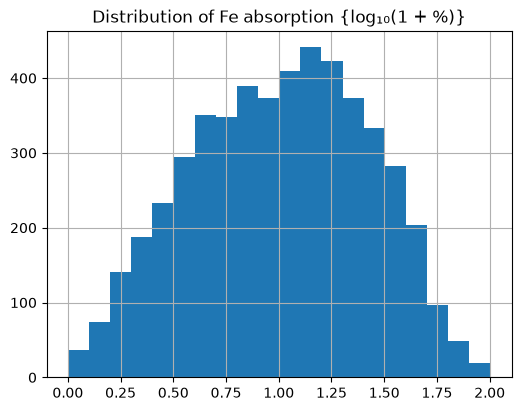

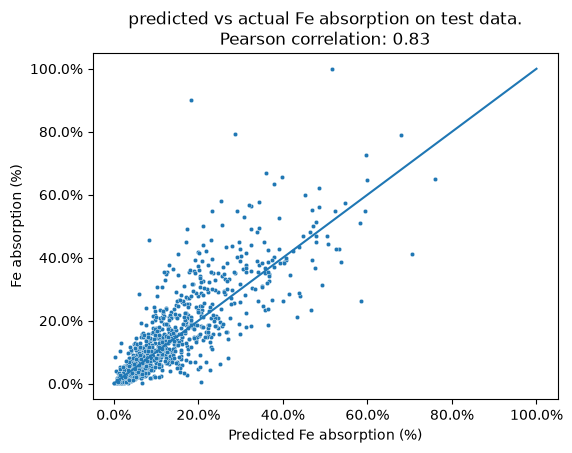

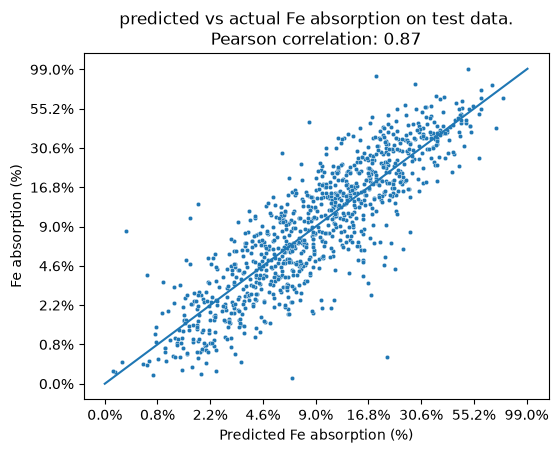

In [5]:
# (A) distribution of the log-transformed target
fig, ax = plt.subplots(figsize=(6, 4.5))
y.hist(bins=20, ax=ax)
ax.set_title("Distribution of Fe absorption {log\u2081\u2080(1 + %)}")
fig.savefig("../figures/panels/SuppFig1A.png", dpi=300, bbox_inches="tight"); plt.show()

# (B) predicted vs observed, % scale
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.scatterplot(x=10 ** y_pred - 1, y=10 ** y_test - 1, s=10, ax=ax)
sns.lineplot(x=[0, 100], y=[0, 100], ax=ax)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, t: f"{v:.1f}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, t: f"{v:.1f}%"))
ax.set_xlabel("Predicted Fe absorption (%)"); ax.set_ylabel("Fe absorption (%)")
ax.set_title("predicted vs actual Fe absorption on test data.\nPearson correlation: {}".format(
    round(pearsonr(10 ** y_pred - 1, 10 ** y_test - 1).statistic, 2)))
fig.savefig("../figures/panels/SuppFig1B.png", dpi=300, bbox_inches="tight"); plt.show()

# (C) predicted vs observed, log10(1 + %) axes labelled in %
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.scatterplot(x=y_pred, y=y_test, s=10, ax=ax)
sns.lineplot(x=[0, np.log10(101)], y=[0, np.log10(101)], ax=ax)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, t: f"{round(10 ** v - 1, 1)}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, t: f"{round(10 ** v - 1, 1)}%"))
ax.set_xlabel("Predicted Fe absorption (%)"); ax.set_ylabel("Fe absorption (%)")
ax.set_title("predicted vs actual Fe absorption on test data.\nPearson correlation: {}".format(
    round(pearsonr(y_pred, y_test).statistic, 2)))
fig.savefig("../figures/panels/SuppFig1C.png", dpi=300, bbox_inches="tight"); plt.show()

## 5. Supplementary Figure 4: SHAP force plots

Representative low-, medium- and high-absorption cases from the held-out test set. f(x) is the
prediction on the log10(1 + %) scale; red features increase and blue features decrease the prediction.

low: observed 0.4%, predicted 3.4% (f(x) = 0.65)


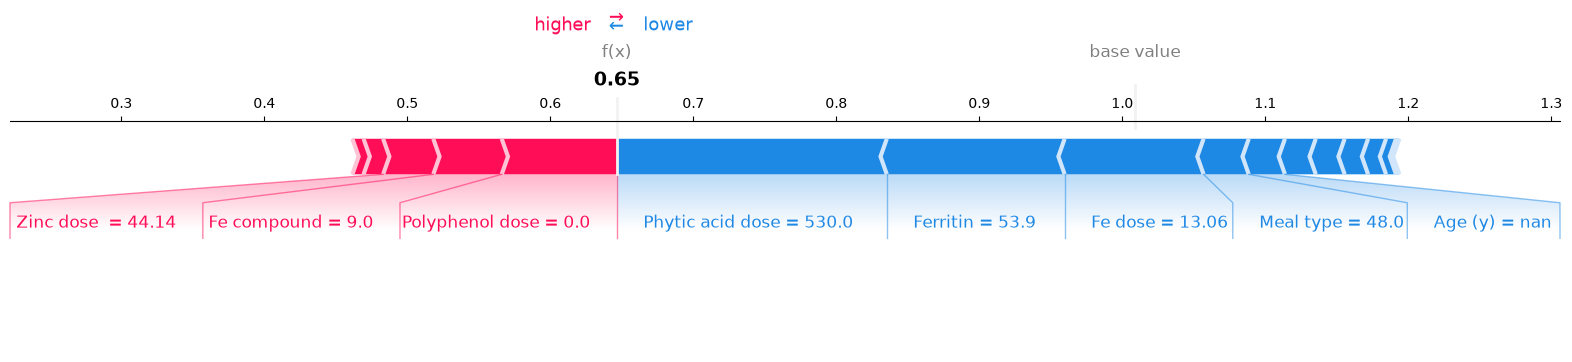

medium: observed 10.4%, predicted 12.0% (f(x) = 1.11)


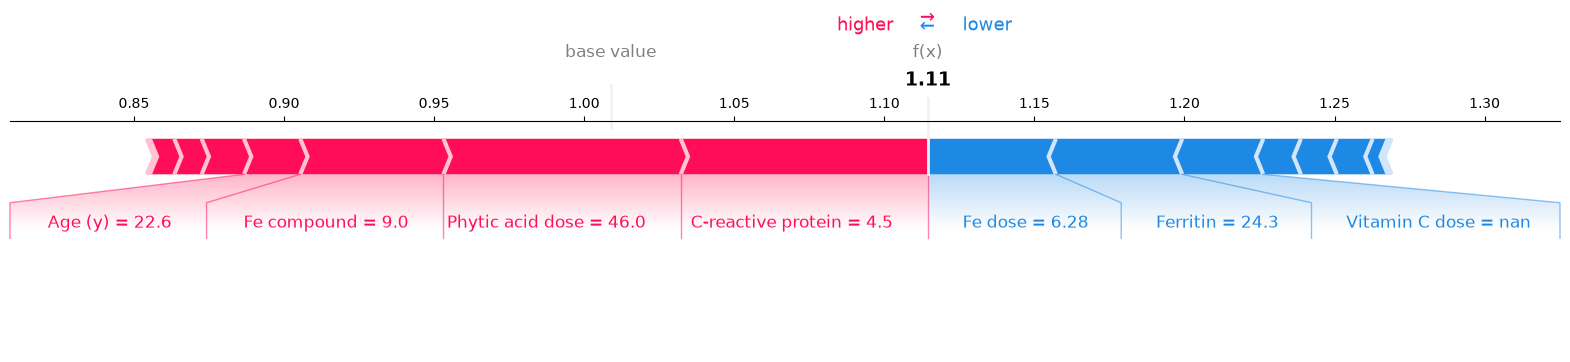

high: observed 39.6%, predicted 23.3% (f(x) = 1.39)


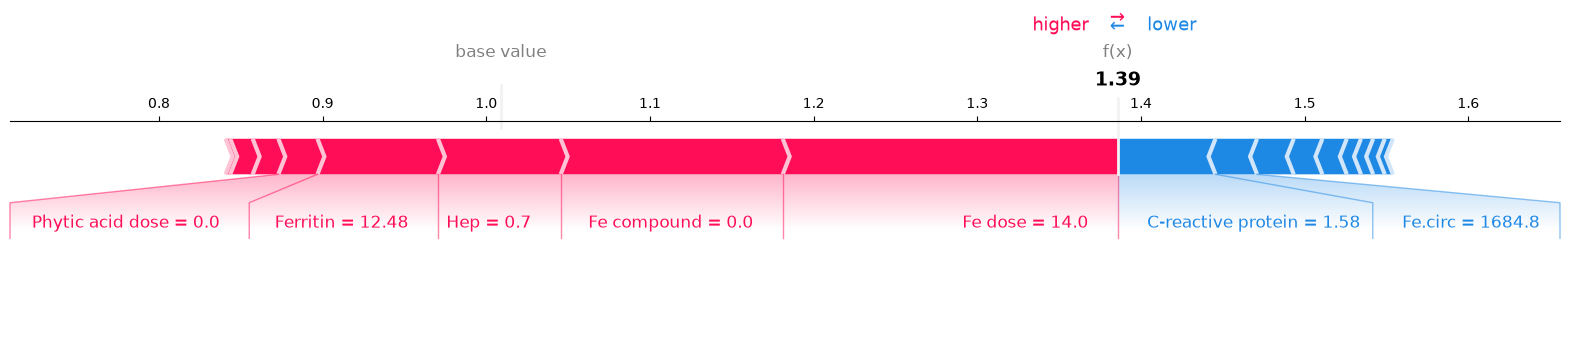

In [6]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

for i, name in [(0, "low"), (2, "medium"), (12, "high")]:
    obs, pred = y_test.iloc[i], y_pred[i]
    print(f"{name}: observed {10 ** obs - 1:.1f}%, predicted {10 ** pred - 1:.1f}% (f(x) = {pred:.2f})")
    fig = shap.force_plot(explainer.expected_value, shap_values[i, :], X_test.iloc[i, :],
                          matplotlib=True, show=False)
    fig.savefig(f"../figures/panels/SuppFig4_{name}.pdf", bbox_inches="tight")
    fig.savefig(f"../figures/panels/SuppFig4_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()